In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/utkarshx27/heart-disease-diagnosis-dataset/dataset_heart.csv


Libraries imported successfully!

Available CSV files:
/kaggle/input/datasets/utkarshx27/heart-disease-diagnosis-dataset/dataset_heart.csv

Dataset loaded successfully!
Dataset shape: (270, 14)

First Five Records:
   age  sex   chest pain type  resting blood pressure  serum cholestoral  \
0   70     1                4                     130                322   
1   67     0                3                     115                564   
2   57     1                2                     124                261   
3   64     1                4                     128                263   
4   74     0                2                     120                269   

   fasting blood sugar  resting electrocardiographic results  max heart rate  \
0                    0                                     2             109   
1                    0                                     2             160   
2                    0                                     0             141   
3       

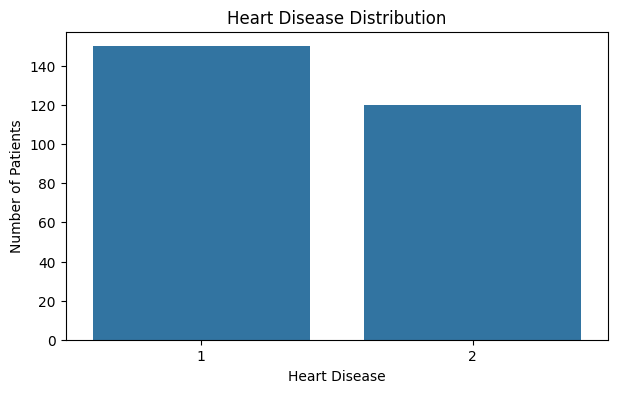


Training records: 216
Testing records: 54

Model trained successfully!

Model Accuracy: 81.48%

Classification Report:
              precision    recall  f1-score   support

           1       0.86      0.80      0.83        30
           2       0.77      0.83      0.80        24

    accuracy                           0.81        54
   macro avg       0.81      0.82      0.81        54
weighted avg       0.82      0.81      0.82        54



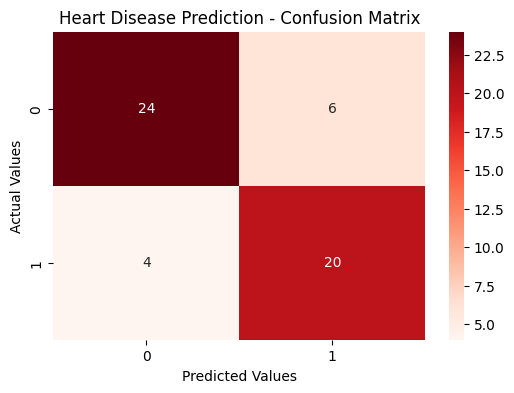

Button(button_style='danger', description='❤️ PREDICT NOW', layout=Layout(height='45px', width='250px'), style…

Output()


 HEART DISEASE PREDICTION PROJECT
Dataset: dataset_heart.csv
Total Records: 270
Algorithm: Random Forest Classifier
Model Accuracy: 81.48%
Project executed successfully!


In [2]:
# ORIGINAL PROJECT
# Developed by: Jayashree V
# Presidency University
# BTech Artificial Intelligence and Data Science
# Academic Year: 2026
# ==========================================================
# HEART DISEASE PREDICTION USING MACHINE LEARNING
# Introduction to Data Science Project
# ==========================================================

# STEP 1: IMPORT LIBRARIES

import os
import glob
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

print("Libraries imported successfully!")


# STEP 2: LOAD DATASET

csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

if not csv_files:
    raise FileNotFoundError(
        "Dataset not found. Please attach your dataset using Add Input."
    )

print("\nAvailable CSV files:")
for f in csv_files:
    print(f)

file_path = next(
    (f for f in csv_files if "heart" in os.path.basename(f).lower()),
    csv_files[0]
)

df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)


# STEP 3: EXPLORE DATASET

print("\nFirst Five Records:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Description:")
print(df.describe(include="all"))


# STEP 4: IDENTIFY TARGET COLUMN

# Your uploaded dataset uses "heart disease"

target_col = "heart disease"

# Handle possible spaces in column names
df.columns = df.columns.str.strip()

if target_col not in df.columns:
    raise ValueError(
        "Column 'heart disease' not found. Available columns: "
        + str(df.columns.tolist())
    )

df = df.drop_duplicates().copy()
df = df.dropna(subset=[target_col])

X = df.drop(columns=[target_col])
y = df[target_col]

# Convert categorical target values into consistent labels
if y.dtype == "object":
    y = y.astype(str).str.strip()

if y.nunique() < 2:
    raise ValueError("Target must have at least two different classes.")

print("\nTarget column:", target_col)
print("Target classes:", y.unique())


# STEP 5: DATA VISUALIZATION

plt.figure(figsize=(7, 4))

sns.countplot(x=y)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

plt.show()


# STEP 6: DATA PREPROCESSING

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_cols:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_cols)
    )

if categorical_cols:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_cols)
    )

preprocessor = ColumnTransformer(transformers)


# STEP 7: SPLIT DATASET

stratify_value = (
    y if y.value_counts().min() >= 2 else None
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_value
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# STEP 8: CREATE MACHINE LEARNING MODEL

model = Pipeline([
    ("preprocessing", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])


# STEP 9: TRAIN MODEL

model.fit(X_train, y_train)

print("\nModel trained successfully!")


# STEP 10: MODEL PREDICTION AND ACCURACY

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


# STEP 11: CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title("Heart Disease Prediction - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()


# STEP 12: HEART DISEASE APPLICATION DESIGN

display(HTML("""
<div style="
background:linear-gradient(135deg,#720000,#e63946);
padding:25px;
border-radius:15px;
text-align:center;
color:white;">

<h1>❤️ HEART CARE</h1>
<h2>HEART DISEASE PREDICTION SYSTEM</h2>
<h3>Machine Learning Based Application</h3>
<p>Enter Patient Information Below</p>

</div>
"""))


# STEP 13: CREATE PATIENT INPUT FIELDS

input_fields = {}

for col in X.columns:

    if col in categorical_cols:

        options = sorted(
            X[col].dropna().unique().tolist(),
            key=lambda v: str(v)
        )

        input_fields[col] = widgets.Dropdown(
            options=options,
            description=str(col),
            style={"description_width": "initial"},
            layout=widgets.Layout(width="95%")
        )

    else:

        median_value = X[col].median()

        if pd.isna(median_value):
            median_value = 0

        input_fields[col] = widgets.FloatText(
            value=float(median_value),
            description=str(col),
            style={"description_width": "initial"},
            layout=widgets.Layout(width="95%")
        )


# STEP 14: CREATE PREDICT BUTTON

predict_button = widgets.Button(
    description="❤️ PREDICT NOW",
    button_style="danger",
    layout=widgets.Layout(
        width="250px",
        height="45px"
    )
)

result_output = widgets.Output()


# STEP 15: PREDICTION FUNCTION

def predict_heart(button):

    with result_output:

        clear_output(wait=True)

        patient_data = pd.DataFrame([{
            col: field.value
            for col, field in input_fields.items()
        }])

        prediction = model.predict(patient_data)[0]

        classes = list(model.named_steps["classifier"].classes_)

        # Determine the positive disease class
        positive_labels = {
            "1", "1.0", "yes", "true",
            "positive", "disease", "present"
        }

        positive_class = next(
            (
                c for c in classes
                if str(c).strip().lower() in positive_labels
            ),
            max(classes) if all(
                isinstance(c, (int, float, np.integer, np.floating))
                for c in classes
            ) else classes[-1]
        )

        display(HTML("""
        <div style="
        background:#eeeeee;
        padding:15px;
        border-radius:10px;
        text-align:center;">
        <h2>Prediction Result</h2>
        </div>
        """))

        if prediction == positive_class:

            display(HTML("""
            <div style="
            background:#ffe0e0;
            padding:25px;
            border-radius:12px;
            text-align:center;
            color:#a00000;">

            <h1>⚠️ Heart Disease Detected</h1>
            <h3>Model Prediction: Positive</h3>
            <p>Please consult a qualified doctor.</p>

            </div>
            """))

        else:

            display(HTML("""
            <div style="
            background:#dcfce7;
            padding:25px;
            border-radius:12px;
            text-align:center;
            color:#166534;">

            <h1>💚 No Heart Disease Detected</h1>
            <h3>Model Prediction: Negative</h3>
            <p>This is only a machine learning prediction.</p>

            </div>
            """))

        print("\nPatient Details:")
        display(patient_data)

        print("\nModel Accuracy: {:.2f}%".format(
            accuracy * 100
        ))


predict_button.on_click(predict_heart)


# STEP 16: DISPLAY APPLICATION

display(HTML("""
<h2 style="color:#e63946;">
👤 Patient Information
</h2>
<p>Enter the patient's details to get a prediction.</p>
"""))

display(widgets.VBox(list(input_fields.values())))

display(predict_button)

display(result_output)


# STEP 17: FINAL PROJECT SUMMARY

print("\n======================================")
print(" HEART DISEASE PREDICTION PROJECT")
print("======================================")
print("Dataset:", os.path.basename(file_path))
print("Total Records:", len(df))
print("Algorithm: Random Forest Classifier")
print("Model Accuracy: {:.2f}%".format(accuracy * 100))
print("Project executed successfully!")
print("======================================")